
<div align="center" style="font-family: 'Garamond', serif; color: #333333;">
    <h2 style="color: #8b0000; text-decoration: underline; font-variant: small-caps;">
        <span style="font-family: 'Courier New', monospace;">&#9472;</span>
        Machine Learning for Autonomous Robots WiSe '26/'27
        <span style="font-family: 'Courier New', monospace;">&#9472;</span>
    </h2>
    <h2 style="color: #6c757d;">Prof. Dr. Frank Kirchner</h2>
    <h4 style="color: #6c757d; font-style: italic;">Exercise Sheet – 1</h4>
    <h5 style="color: #6c757d;">Due: 17.11.2026</h5>
    <hr style="border-top: 2px solid #8b0000; width: 100%;">
</div>

Please provide the group number (from stud.ip) and list of contributing team members in the following format in the next markdown cell:

Group number <>
* name - email
* name - email
* ...

YOUR ANSWER HERE

# Problem 1: Feature Selection (12 Points Total)

We start off this exercise sheet with an easy implementation of the feature selection methods that were covered in the lecture. In this problem 1, we are first gonna import the **iris** dataset from the scikit-learn library. Then you are gonna calculate correlations between different feature pairs and between feature and class pairs. After that, you are gonna calculate the merit of the given feature set. Finally, you are gonna finish off this problem by implementing the GreedyCFS algorithm outlined in the lecture slides.

### **1A:** Implement correlation calculation and merit calculation. **(4 Points Total)**

In the following code cell, the **iris** dataset has already been imported for you from the scikit-learn library. Your job is to calculate the correlations between different feature pairs and feature-class pairs. You are free to use suitable numpy functions to calculate these correlations. After that, you will calculate the merits for the given feature set in the same code cell below. The respective correlation and merit calculations should be under their corresponding function definitions. This task **1A** contains **4 points** total, with **2 points** each for the correlation and merit calculations.

In [1]:
'''Implementation for 1A'''

import numpy as np
import itertools
from sklearn.datasets import load_iris


def load_dataset():
    """
    Loads the iris data set and returns its features and labels.

    Returns
    -------
    X, y : ndarray, ndarray
        Arrays with features and labels respectively
    """
    X, y = load_iris(return_X_y=True)
    return X, y


def calculate_abs_correlation(X, y):
    """
    Calculates the feature-feature correlation and the feature-class correlation of the provided data.

    Parameters
    ----------
    X : ndarray 
        Features of the Dataset

    y : ndarray 
        labels of the Dataset

    Returns
    -------
    correlation_matrix : ndarray 
        Correlation Matrix
    """
    # Version B: Pearson correlation coefficient written out as on the
    # lecture slide "Correlation coefficient (1/2)":
    #   r(f_i, f_j) = sum_k (X[k,i] - mean_i)(X[k,j] - mean_j)
    #                 / ( sqrt(sum_k (X[k,i] - mean_i)^2) * sqrt(sum_k (X[k,j] - mean_j)^2) )
    # The class labels are stacked as an extra (last) column, so that
    # corr[i, j] is |r(f_i, f_j)| and corr[i, -1] is |r(f_i, class)|.
    data = np.column_stack((X, y)).astype(float)
    centered = data - data.mean(axis=0)               # X[k,i] - mean_i
    numerator = centered.T @ centered                 # sum_k over all (i, j) pairs
    norms = np.sqrt((centered ** 2).sum(axis=0))      # sqrt(sum_k (X[k,i] - mean_i)^2)
    correlation_matrix = np.abs(numerator / np.outer(norms, norms))
    return correlation_matrix

def calculate_merit(X, y, feature_set):
    """
    Calculates the merit for the given feature set.

    Parameters
    ----------
    X : ndarray 
        Features of the Dataset

    y : ndarray 
        labels of the Dataset

    feature_set: list

    Returns
    -------
    merit : float 
        The merit for the feature set
    """
    k = len(feature_set)
    if k == 0:
        return 0.0  # merit of the empty set is defined as 0

    corr = calculate_abs_correlation(X, y)
    class_idx = X.shape[1]  # the class is the last column of the correlation matrix

    # average absolute feature-class correlation
    fcr = np.mean([corr[f, class_idx] for f in feature_set])

    # average absolute feature-feature correlation (no auto-correlations, |r_ff| := 1 for one feature)
    if k == 1:
        frr = 1.0
    else:
        frr = np.mean([corr[i, j] for i, j in itertools.combinations(feature_set, 2)])

    # merit(F') = |F'| * fcr / sqrt(|F'| + |F'| * (|F'| - 1) * frr)
    merit = k * fcr / np.sqrt(k + k * (k - 1) * frr)
    return float(merit)

### **1B:** Correlation Computation and Documentation. **(2 Points Total)**

For this exercise **1B**, you will need to study the preprocessing lecture and lecture slides carefully. You would have to first download the **iris** dataset from the scikit-learn library. After that, for each subset of feature pairs, you will need to compute and document the average feature-class correlation $\overline{\vert r_{fc}\vert}$, the average feature-feature correlation $\overline{\vert r_{ff}\vert}$ and the `merit` as outlined and explained in the lecture slides. The final output generated by you should resemble the tabular format depicted below. The exact correlation and merit values might be different, but the output format should be the same as below. Make sure to implement this in the code cell below.

| Feature Set   | Merit              | frr                 | fcr                |
|---------------|--------------------|---------------------|--------------------|
| []            | 0                  | None                | None               |
| [0]           | 0.782561231810082  | 1                   | 0.782561231810082  |
| [1]           | 0.4266575607811244 | 1                   | 0.4266575607811244 |
| [2]           | 0.9490346990083889 | 1                   | 0.9490346990083889 |
| [3]           | 0.9565473328764036 | 1                   | 0.9565473328764036 |
| [0, 1]        | 0.8088212717496626 | 0.11756978413300204 | 0.6046093962956032 |
| [0, 2]        | 0.8949673665149928 | 0.8717537758865832  | 0.8657979654092354 |
| [0, 3]        | 0.9120565965611317 | 0.8179411262715756  | 0.8695542823432427 |
| [1, 2]        | 0.8139079274947801 | 0.4284401043305395  | 0.6878461298947567 |
| [1, 3]        | 0.8368086315382556 | 0.36612593253643944 | 0.691602446828764  |
| [2, 3]        | 0.9617615000216455 | 0.962865431402796   | 0.9527910159423962 |
| [0, 1, 2]     | 0.8934338412645652 | 0.4725878881167082  | 0.7194178305331983 |
| [0, 1, 3]     | 0.9149358372249947 | 0.4338789476470057  | 0.7219220418225367 |
| [0, 2, 3]     | 0.9327804542434761 | 0.8841867778536515  | 0.896047754564958  |
| [1, 2, 3]     | 0.9137355503457556 | 0.5858104894232583  | 0.7774131975553056 |
| [0, 1, 2, 3]  | 0.9336724737073916 | 0.594116025760156   | 0.7787002061189996 |

In [2]:
'''Implementation for 1B'''

import pandas as pd

X, y = load_dataset()
corr = calculate_abs_correlation(X, y)
n_features = X.shape[1]
class_idx = n_features  # the class is the last column of the correlation matrix

rows = []
# all subsets of the features, ordered by cardinality: [], [0], ..., [0, 1, 2, 3]
for k in range(n_features + 1):
    for feature_set in itertools.combinations(range(n_features), k):
        feature_set = list(feature_set)
        if k == 0:
            frr, fcr = None, None
        else:
            fcr = float(np.mean([corr[f, class_idx] for f in feature_set]))
            if k == 1:
                frr = 1.0
            else:
                frr = float(np.mean([corr[i, j] for i, j in itertools.combinations(feature_set, 2)]))
        merit = calculate_merit(X, y, feature_set)
        rows.append({"Feature Set": feature_set, "Merit": merit, "frr": frr, "fcr": fcr})

# dtype=object keeps None as None; formatters=str prints the floats with full precision
df = pd.DataFrame(rows, dtype=object)
print(df.to_string(index=False, formatters={col: str for col in ["Merit", "frr", "fcr"]}))

 Feature Set              Merit                 frr                fcr
          []                0.0                None               None
         [0] 0.7825612318100822                 1.0 0.7825612318100822
         [1] 0.4266575607811246                 1.0 0.4266575607811246
         [2] 0.9490346990083878                 1.0 0.9490346990083878
         [3] 0.9565473328764031                 1.0 0.9565473328764031
      [0, 1] 0.8088212717496629 0.11756978413300206 0.6046093962956034
      [0, 2] 0.8949673665149924   0.871753775886583 0.8657979654092349
      [0, 3] 0.9120565965611316  0.8179411262715759 0.8695542823432427
      [1, 2] 0.8139079274947795  0.4284401043305401 0.6878461298947562
      [1, 3] 0.8368086315382552  0.3661259325364395 0.6916024468287638
      [2, 3] 0.9617615000216448  0.9628654314027958 0.9527910159423955
   [0, 1, 2] 0.8934338412645648 0.47258788811670843 0.7194178305331982
   [0, 1, 3] 0.9149358372249946  0.4338789476470058 0.7219220418225367
   [0,

### **1C:** GreedyCFS Implementation. **(4 Points Total)**

In this exercise **1C**, you will implement the **GreedyCFS** algorithm based on the Greedy Hill-Climbing Heuristic, as outlined in the lecture slides. Please make sure that your implementation is contained under the **greedy_cfs(X, y)** function definition in the code cell below and **don't** create a new function definition for implementing the GreedyCFS algorithm.

In [3]:
'''Implementation for 1C'''

def greedy_cfs(X, y):
    """
    Performs greedy hill-climbing feature selection based on merit.

    Parameters
    ----------
    X : ndarray 
        Features of the Dataset

    y : ndarray 
        labels of the Dataset


    Returns
    -------
    selected_features : list(int) 
        List with the selected features    
    """
    remaining = list(range(X.shape[1]))  # F
    selected_features = []               # F'

    while remaining:  # stop as well when every feature has been added
        last_merit = calculate_merit(X, y, selected_features)
        candidate_merits = [calculate_merit(X, y, selected_features + [f]) for f in remaining]
        best = int(np.argmax(candidate_merits))  # f_sel = argmax_f merit(F' u {f})
        if candidate_merits[best] < last_merit:
            break
        selected_features.append(remaining.pop(best))  # F' <- F' u {f_sel}, F <- F \ {f_sel}

    return selected_features


"""
Run feature selection.
"""
X, y = load_dataset()
selected_features = greedy_cfs(X, y)
print(f"The selected features are: {selected_features}.")

The selected features are: [3, 2].


### **1D:** Features Merit and Cardinality. **(2 Points Total)**

This exercise **1D** only contains a question that you should be able to answer correctly if you followed the lecture carefully and studied the lecture slides diligently.

Which subset(s) of features with cardinality $2$ would be optimal according to the merit and which subset of features with arbitrary cardinality would be optimal according to the merit?

Answer the question above in the markdown cell below.

**Cardinality 2:** the optimal subset is **[2, 3]** (petal length, petal width) with merit $\approx 0.9618$. It is the only pair whose merit beats the best single feature ([3], merit $\approx 0.9565$): both features are very strongly correlated with the class ($\overline{\vert r_{fc}\vert} \approx 0.953$), which outweighs their high mutual redundancy ($\overline{\vert r_{ff}\vert} \approx 0.963$). The next best pair, [0, 3], only reaches $\approx 0.9121$.

**Arbitrary cardinality:** the optimal subset is again **[2, 3]**, i.e. $F'_{opt} = \arg\max_{F' \subseteq F} \text{merit}(F') = \{2, 3\}$ with merit $\approx 0.9618$, the highest value in the whole table. Adding a third feature always lowers the merit (best triple [0, 2, 3]: $\approx 0.9328$; all four features: $\approx 0.9337$), because each extra feature adds less class correlation than it adds redundancy. This is also the subset found by GreedyCFS in 1C ([3] first, then [2], then it stops).

# Problem 2: Principal Component Analysis (8 Points Total)

This second problem of this exercise sheet consists of **PCA** implementation from scratch. In the first part of this problem **2**, you will implement **PCA** from scratch by studying the **PCA** algorithm outlined in the **preprocessing** lecture slides. The second part will consist of explaining the results that you obtained from your PCA implementation. Upon correct and successful completion of this problem, you will receive **8 points** in total. 

### **2A:** PCA implementation from scratch. **(6 Points Total)**

Your job is to go through the **PCA** section of the **preprocessing** lecture slides and implement the PCA algorithm from scratch as depicted in the slides. Please keep in mind that you cannot use the `cov` function of numpy and will need to calculate the covariance by yourself. Use the `load_dataset` function to load the data, apply your PCA and plot 3 different combinations of principal components.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /Users/muhammednasim/scikit_learn_data


data: 400 images with 4096 pixels each, image shape (64, 64)


eigen_vectors: (200, 4096), eigen_values: (200,)
variance explained by the first   5 components: 54.4%
variance explained by the first  50 components: 87.4%
variance explained by the first 200 components: 97.9%


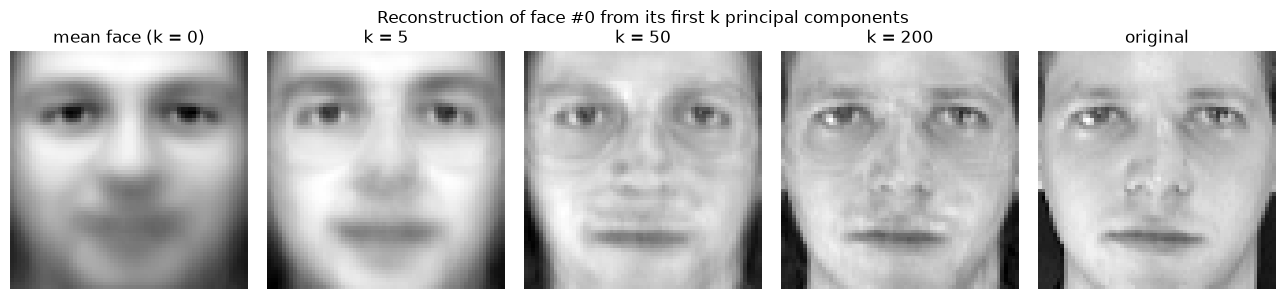

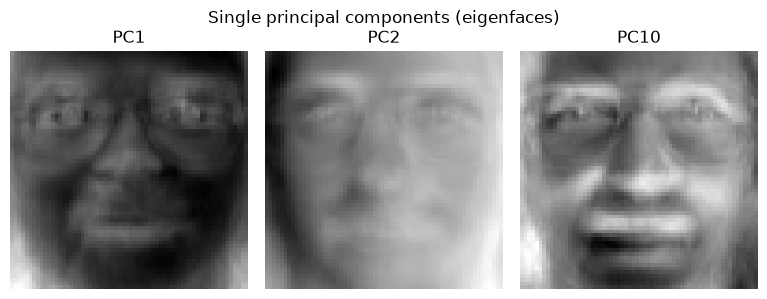

In [4]:
'''Implementation for 2 '''

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces


def pca(data, k):
    '''
    Performs PCA on given data.

    Parameters
    ----------
    data: ndarray of shape (NxM)
        Data

    k: int
        number of eigenvectors to return

    Returns
    -------
    eigen_vectors, eigen_values : ndarray, ndarray 
        eigenvectors (NxM), eigenvalues (N) for the data    
    '''
    n = data.shape[0]

    # Subtract the empirical mean: X <- X - mean(X)
    mean = data.mean(axis=0)
    X = data - mean

    # Empirical M x M covariance matrix: Sigma = (n - 1)^-1 * X^T X  (np.cov is not allowed)
    sigma = (X.T @ X) / (n - 1)

    # Eigendecomposition Sigma W = W Lambda. Sigma is symmetric, so eigh gives real
    # eigenvalues/eigenvectors; it returns them in ascending order, so sort descending.
    eigen_values, W = np.linalg.eigh(sigma)
    order = np.argsort(eigen_values)[::-1][:k]

    # Columns of W are the eigenvectors -> return the first k as rows (k x M)
    eigen_vectors = W[:, order].T
    eigen_values = eigen_values[order]
    return eigen_vectors, eigen_values

def showVec(img, shape):
    ''' 
    reshapes vector to given image size and plots it
    len(img) must be shape[0]*shape[1]

    Parameters
    ----------
    img: ndarray
        given image as 1d vector

    shape: tuple
        shape of image

    '''
    img = np.reshape(img, shape)
    plt.imshow(img, cmap="gray")
    plt.show()

 
def normalized_linear_combination(vecs, weights):
    '''
    Computes a linear combination of given vectors and weights.
    len(weights) must be <= vecs.shape[0]

    Parameters
    ----------
    vecs: ndarray
        ndarray of ndarrays to combine (NxM, N = number of basis vectors (unitary or eigenvectors))

    weights: list 
        list of weights (S) for the first S vectors


    Returns
    -------
    vec : ndarray
        normalized linear combinations in a ndarray of shape [M,1]
    '''
    weights = np.asarray(weights, dtype=float)
    # sum_i w_i * vecs[i] over the first S = len(weights) vectors
    vec = weights @ vecs[:len(weights)]
    # min-max normalisation to [0, 1], so the result can be shown as an image
    vec = (vec - vec.min()) / (vec.max() - vec.min())
    return vec.reshape(-1, 1)

#load and scale down images
def load_dataset():
    '''
    Load data and transforms the values from [0,1] to [0,255]

    Returns
    -------
    data, shape: ndarray, tuple
        tuple of data (N,M) and shape of one img, N = number of samples, M = size of sample
    '''
    data = fetch_olivetti_faces().data

    data = np.round(data * 255)

    return data, (64, 64)


'''
TODO
1) Load dataset
2) compute principal components
3) compute linear combinations
4) display stuff
'''
def show_grid(images, titles, shape, suptitle):
    """Plots several image vectors side by side in one figure."""
    fig, axes = plt.subplots(1, len(images), figsize=(2.6 * len(images), 3.0))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(np.reshape(img, shape), cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


# 1) Load dataset
data, shape = load_dataset()
print(f"data: {data.shape[0]} images with {data.shape[1]} pixels each, image shape {shape}")

# 2) Compute principal components
k = 200
eigen_vectors, eigen_values = pca(data, k)
mean_face = data.mean(axis=0)
print(f"eigen_vectors: {eigen_vectors.shape}, eigen_values: {eigen_values.shape}")
# total variance = trace(Sigma) = sum of all eigenvalues
total_variance = ((data - mean_face) ** 2).sum() / (data.shape[0] - 1)
for n_pc in [5, 50, 200]:
    print(f"variance explained by the first {n_pc:3d} components: {eigen_values[:n_pc].sum() / total_variance:.1%}")

# 3) Compute linear combinations
# Combination group 1: reconstruct face #0 from its first k principal components.
# The mean face is used as an extra basis vector with weight 1, so that
#     mean + sum_i w_i * pc_i,   with w_i = (face - mean) . pc_i
# is a single linear combination that normalized_linear_combination can scale for display.
face = data[0]
basis = np.vstack([mean_face, eigen_vectors])
weights = eigen_vectors @ (face - mean_face)  # projection of the face onto each component

recon_ks = [5, 50, 200]
group1 = [normalized_linear_combination(basis, [1.0])]  # mean face only (k = 0)
group1 += [normalized_linear_combination(basis, [1.0] + list(weights[:n_pc])) for n_pc in recon_ks]
group1 += [normalized_linear_combination(face[np.newaxis, :], [1.0])]  # original face
titles1 = ["mean face (k = 0)"] + [f"k = {n_pc}" for n_pc in recon_ks] + ["original"]

# Combination group 2: single principal components ("eigenfaces")
single_pcs = [1, 2, 10]
group2 = [normalized_linear_combination(eigen_vectors, [0.0] * (pc - 1) + [1.0]) for pc in single_pcs]
titles2 = [f"PC{pc}" for pc in single_pcs]

# 4) Display stuff
show_grid(group1, titles1, shape, "Reconstruction of face #0 from its first k principal components")
show_grid(group2, titles2, shape, "Single principal components (eigenfaces)")

### **2B:** Interpretation of PCA Implementation. **(2 Points Total)**

Explain the differences of your plotted combinations of principal components?

**Reconstruction of face #0 (mean + first $k$ components):**

- **Mean face ($k = 0$):** the average of all 400 images. A blurry, generic face with no identity: every reconstruction starts from it, because PCA subtracts the mean first.
- **$k = 5$ (≈ 54 % of the variance):** still mostly the mean face. Only the coarsest, most variable properties change, such as overall brightness, lighting and head/face outline. The person is not yet recognisable.
- **$k = 50$ (≈ 87 %):** the identity appears: the face shape, hairline, eyes, nose and mouth start to look like the original. There are still "ghost" artefacts (e.g. faint glasses-like rings) because 50 components cannot cancel out everything the basis has learned from other faces.
- **$k = 200$ (≈ 98 %):** very close to the original. Fine, high-frequency details (eyebrows, nostrils, the edges of the face) are mostly back; only some sharpness and small noise are missing.

The difference between the combinations is the number of principal components used. Components are sorted by eigenvalue (variance), so the first ones capture the large-scale structure shared by many faces and later ones add progressively finer, more individual detail with less variance each. That is why a few components already give a rough face, while exact reconstruction needs many more (and with all components it would be exact).

**Single principal components (eigenfaces):**

- **PC1** (largest variance): a global, low-frequency pattern (the whole face is dark against a bright background), i.e. mainly overall illumination / face-vs-background contrast, which varies most between the images.
- **PC2:** another smooth, global pattern with only faint facial features, i.e. mostly a different lighting/brightness variation across the face.
- **PC10:** much more local, higher-frequency structure: glasses, eyebrows, eyes and especially the mouth/lips stand out. Lower-ranked components describe such specific features that differ only between some of the people.

Note: the sign of an eigenvector is arbitrary ($w$ and $-w$ are both eigenvectors), so an eigenface could just as well appear inverted (dark ↔ bright); only the pattern matters.


<div align="center" style="font-family: 'Garamond', serif; color: #333333;">
    <hr style="border-top: 2px solid #8b0000; width: 100%;">
    <p style="color: #6c757d;">
        Please upload your submission via JupyterHub by 23:59 on 17.11.2026. If you encounter any issues with the upload process, please contact the Machine Learning Course Team in advance at <a href="ml-course@dfki.de" style="color: #8b0000;">ml-course@dfki.de</a>. Your submission must include:
    </p>
    <ul style="list-style-type: none; color: #6c757d;">
        <li>&#9472; A well-documented, precompiled notebook, containing the entire solution(s) along with outputs and plots if applicable</li>
        <li>&#9472; A markdown cell with the names and e-mail addresses of the contributing team members</li>
        <li>&#9472; All markdown answer cells filled in — code-only submissions without written analysis will receive partial credit at most</li>
    </ul>
    <hr style="border-top: 2px solid #8b0000; width: 100%;">
</div>
